In [ ]:
import sys
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Configuration
sample_idx = 6000
data_size = 256
sos_path = '/afs/L202500118/wangjt/datasets/openfwi/CurveFault_B'

# ==============================================================================
# 1. Load velocity (sos) data for sample 6000
# ==============================================================================
# For openfwi_CurveFault_B, the file naming convention is:
# file_id = idx // 500, data_id = idx % 500
# filename: vel{(file_id//36)+6}_1_{file_id%36}.npy
file_id = sample_idx // 500
data_id = sample_idx % 500
filename = f"vel{(file_id//36)+6}_1_{file_id%36}.npy"
print(f"Loading velocity data from: {os.path.join(sos_path, filename)}")

# Data shape: (500, 1, 70, 70)
sos_data = np.load(os.path.join(sos_path, filename))
sos = sos_data[data_id]  # shape: (1, 70, 70)

# Interpolate to target size (256x256) using torch
sos_tensor = torch.from_numpy(sos).unsqueeze(0).float()  # (1, 1, 70, 70)
sos_tensor = F.interpolate(sos_tensor, size=(data_size, data_size), mode='bilinear', align_corners=False)
sos_np = sos_tensor.squeeze().numpy()  # (256, 256)

print(f"Velocity shape: {sos_np.shape}")

# ==============================================================================
# 2. Load wavefield solution (u_cbs_6000.pth)
# ==============================================================================
u_path = '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/cbs/wavefield/u_cbs_6000.pth'
u = torch.load(u_path, weights_only=False)
# Extract real part - shape is (1, 1, 320, 320) with PML boundaries
u_real = torch.view_as_real(u)[0, 0, :, :, 0].cpu().numpy()
print(f"Wavefield shape: {u_real.shape}")

# ==============================================================================
# 3. Load iteration histories for 4 methods
# ==============================================================================
iter_history_paths = {
    'CBS': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/cbs/iter_history/iter_history_cbs_6000.pth',
    'NPBS(MgNO)': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/ppw12/mgno_bs_pre/iter_history/iter_history_mgno_bs_6000.pth',
    'FGMRES+CBS': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/cbs_gmres/iter_history/iter_history_cbs_6000.pth',
    'FGMRES+NPBS(MgNO)': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/ppw12/mgno_bs_pre_gmres/iter_history/iter_history_mgno_bs_6000.pth',
}

iter_histories = {}
for name, path in iter_history_paths.items():
    data = torch.load(path, weights_only=False)
    # The saved data is a dict with 'iter_log' key
    if isinstance(data, dict):
        iter_histories[name] = data['iter_log']
    else:
        iter_histories[name] = data
    print(f"{name}: {len(iter_histories[name])} iterations")

# ==============================================================================
# 4. Plot 1x3 figure
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Column 1: Velocity (Speed of Sound) ---
img0 = axes[0].imshow(sos_np, interpolation='none', cmap='jet')
axes[0].set_title('Speed of Sound', fontsize=14)
fig.colorbar(img0, ax=axes[0], fraction=0.046, pad=0.04)
# Mark source position (size//10, size//2)
src_pos = [data_size // 10, data_size // 2]
axes[0].scatter(src_pos[1], src_pos[0], s=100, c='w', marker='x')

# --- Column 2: Wavefield (Real part) ---
vmax = np.max(u_real) * 0.6
img1 = axes[1].imshow(u_real, interpolation='none', cmap='seismic', vmin=-vmax, vmax=vmax)
axes[1].set_title('Wavefield Real', fontsize=14)
fig.colorbar(img1, ax=axes[1], fraction=0.046, pad=0.04)

# --- Column 3: Iteration History (4 methods) ---
colors = {'CBS': 'blue', 'NPBS(MgNO)': 'red', 'FGMRES+CBS': 'green', 'FGMRES+NPBS(MgNO)': 'orange'}
linestyles = {'CBS': '-', 'NPBS(MgNO)': '--', 'FGMRES+CBS': '-', 'FGMRES+NPBS(MgNO)': '--'}
markers = {'CBS': 'o', 'NPBS(MgNO)': 'd', 'FGMRES+CBS': 's', 'FGMRES+NPBS(MgNO)': '^'}
for name in ['CBS', 'NPBS(MgNO)', 'FGMRES+CBS', 'FGMRES+NPBS(MgNO)']:
    history = iter_histories[name]
    history.insert(0, 1.0)
    iters = np.arange(len(history)) + 1

    markevery = max(1, len(history) // 15)

    axes[2].semilogy(
        iters, history,
        color=colors[name],
        linestyle=linestyles[name], linewidth=2,
        marker=markers[name], markersize=6, markevery=markevery,
        label=name,
    )

axes[2].set_title('Iteration History', fontsize=14)
axes[2].grid(True)
axes[2].set_xlabel('Iteration', fontsize=12)
axes[2].set_ylabel('Rel residual', fontsize=12)
axes[2].legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.savefig('/afs/L202500118/wangjt/work/precond_loss/helmholtz/bin/plot_exp_result.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure saved to plot_exp_result.png")

Loading velocity data from: /afs/L202500118/wangjt/datasets/openfwi/CurveFault_B/vel6_1_12.npy
Velocity shape: (256, 256)
Wavefield shape: (320, 320)
CBS: 1278 iterations
NPBS(MgNO): 111 iterations
FGMRES+CBS: 537 iterations
FGMRES+NPBS(MgNO): 36 iterations


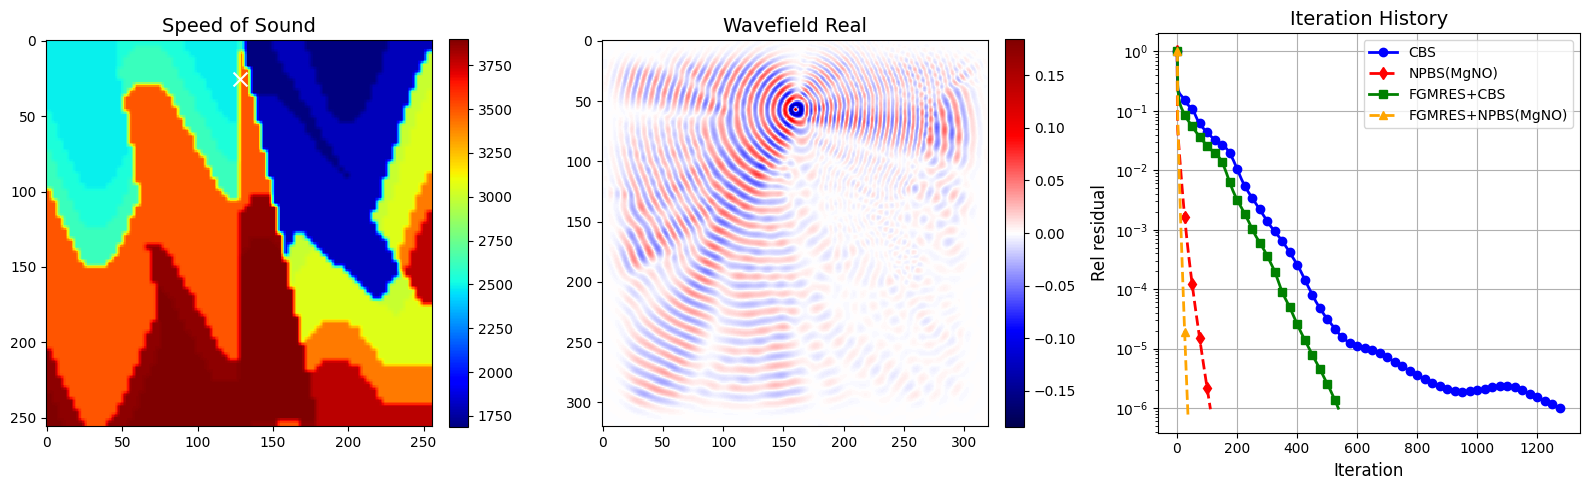

Figure saved to plot_exp_result.png


In [ ]:
import sys
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Configuration
sample_idx = 6000
data_size = 256
sos_path = '/afs/L202500118/wangjt/datasets/openfwi/CurveFault_B'


file_id = sample_idx // 500
data_id = sample_idx % 500
filename = f"vel{(file_id//36)+6}_1_{file_id%36}.npy"
print(f"Loading velocity data from: {os.path.join(sos_path, filename)}")

# Data shape: (500, 1, 70, 70)
sos_data = np.load(os.path.join(sos_path, filename))
sos = sos_data[data_id]  # shape: (1, 70, 70)

sos_tensor = torch.from_numpy(sos).unsqueeze(0).float()  # (1, 1, 70, 70)
sos_tensor = F.interpolate(sos_tensor, size=(data_size, data_size), mode='bilinear', align_corners=False)
sos_np = sos_tensor.squeeze().numpy()  # (256, 256)

print(f"Velocity shape: {sos_np.shape}")

u_path = '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/cbs/wavefield/u_cbs_6000.pth'
u = torch.load(u_path, weights_only=False)
# Extract real part - shape is (1, 1, 320, 320) with PML boundaries
u_real = torch.view_as_real(u)[0, 0, :, :, 0].cpu().numpy()
print(f"Wavefield shape: {u_real.shape}")

iter_history_paths = {
    'CBS': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/cbs/iter_history/iter_history_cbs_6000.pth',
    'NPBS(MgNO)': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/ppw12/mgno_bs_pre/iter_history/iter_history_mgno_bs_6000.pth',
    'FGMRES+CBS': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/cbs_gmres/iter_history/iter_history_cbs_6000.pth',
    'FGMRES+NPBS(MgNO)': '/afs/L202500118/wangjt/work/precond_loss/helmholtz/outputs/2d/openfwi/CurveFault_B/ppw12/mgno_bs_pre_gmres/iter_history/iter_history_mgno_bs_6000.pth',
}

iter_histories = {}
for name, path in iter_history_paths.items():
    data = torch.load(path, weights_only=False)
    # The saved data is a dict with 'iter_log' key
    if isinstance(data, dict):
        iter_histories[name] = data['iter_log']
    else:
        iter_histories[name] = data
    print(f"{name}: {len(iter_histories[name])} iterations")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Column 1: Velocity (Speed of Sound) ---
img0 = axes[0].imshow(sos_np, interpolation='none', cmap='jet')
axes[0].set_title('Speed of Sound', fontsize=14)
fig.colorbar(img0, ax=axes[0], fraction=0.046, pad=0.04)
# Mark source position (size//10, size//2)
src_pos = [data_size // 10, data_size // 2]
axes[0].scatter(src_pos[1], src_pos[0], s=100, c='w', marker='x')

# --- Column 2: Wavefield (Real part) ---
vmax = np.max(u_real) * 0.6
img1 = axes[1].imshow(u_real, interpolation='none', cmap='seismic', vmin=-vmax, vmax=vmax)
axes[1].set_title('Wavefield Real', fontsize=14)
fig.colorbar(img1, ax=axes[1], fraction=0.046, pad=0.04)

# --- Column 3: Iteration History (4 methods) ---
colors = {'CBS': 'blue', 'NPBS(MgNO)': 'red', 'FGMRES+CBS': 'green', 'FGMRES+NPBS(MgNO)': 'orange'}
linestyles = {'CBS': '-', 'NPBS(MgNO)': '--', 'FGMRES+CBS': '-', 'FGMRES+NPBS(MgNO)': '--'}
markers = {'CBS': 'o', 'NPBS(MgNO)': 'd', 'FGMRES+CBS': 's', 'FGMRES+NPBS(MgNO)': '^'}
for name in ['CBS', 'NPBS(MgNO)', 'FGMRES+CBS', 'FGMRES+NPBS(MgNO)']:
    history = iter_histories[name]
    history.insert(0, 1.0)
    iters = np.arange(len(history)) + 1

    markevery = 25

    axes[2].semilogy(
        iters, history,
        color=colors[name],
        linestyle=linestyles[name], linewidth=2,
        marker=markers[name], markersize=6, markevery=markevery,
        label=name,
    )

axes[2].set_title('Iteration History', fontsize=14)
axes[2].grid(True)
axes[2].set_xlabel('Iteration', fontsize=12)
axes[2].set_ylabel('Rel residual', fontsize=12)
axes[2].legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.savefig('/afs/L202500118/wangjt/work/precond_loss/helmholtz/bin/plot_exp_result.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure saved to plot_exp_result.png")